# Practical 4: Data Preprocessing, Noise Elimination, Feature Selection and Exploratory Data Analysis

|  |  |
|---|---|
| **Name** | Aayushman Verma |
| **Roll No.** | 57 |
| **College** | B. K. Birla College, Kalyan |
| **Student ID** | 5176202 |

**Aim:** To use Pandas, NumPy, Scikit-learn, Matplotlib and Seaborn to clean a data set (missing values and duplicates), scale it (normalisation and standardisation), remove noise, select the useful features and explore the data with statistics and plots (EDA).

## Part A: Cleaning, Normalization and Standardization

A synthetic housing data set (32 rows) is generated with deliberate problems: missing numbers and text, two duplicate rows, a constant column, a redundant column (price in lakh) and two noisy prices.

In [1]:
# Name: Ayushman Rajeev Verma
# PART A : data cleaning and scaling on a housing data set
print("Name: Ayushman Rajeev Verma")
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

rng = np.random.default_rng(7)
n = 30
houses = pd.DataFrame({
    "sqft":      rng.integers(600, 2400, n).astype(float),
    "bedrooms":  rng.integers(1, 5, n).astype(float),
    "age_years": rng.integers(1, 40, n).astype(float),
    "distance_km": np.round(rng.uniform(1, 25, n), 1),
    "city":      rng.choice(["Pune", "Mumbai", "Nashik"], n),
})
houses["price"] = (houses["sqft"] * 4200 - houses["age_years"] * 9000 - houses["distance_km"] * 12000
                   + rng.normal(0, 60000, n)).round(-3)
houses["price_lakh"] = houses["price"] / 100000          # same information as price (redundant)
houses["country_code"] = 91                                # constant column
houses = pd.concat([houses, houses.iloc[[3, 11]]], ignore_index=True)       # 2 duplicate rows
houses.loc[[2, 9, 17], "sqft"] = np.nan                                      # missing numbers
houses.loc[[5, 20], "city"] = None                                           # missing text
houses.loc[[4], "price"] = 45_000_000                                        # extreme price (noise)
houses.loc[[13], "price"] = -250_000                                         # impossible price (noise)

print("Shape:", houses.shape)
print("\nMissing values:\n", houses.isna().sum()[lambda s: s > 0].to_string())
print("\nDuplicate rows:", houses.duplicated().sum())

clean = houses.drop_duplicates().copy()                                      # 1. duplicates
clean["sqft"] = clean["sqft"].fillna(clean["sqft"].median())                 # 2. numeric -> median
clean["city"] = clean["city"].fillna(clean["city"].mode()[0])                #    text -> most common
print("\nAfter cleaning -> rows:", len(clean), "| missing values left:", int(clean.isna().sum().sum()))

cols = ["sqft", "bedrooms", "age_years", "distance_km"]
scaled_mm = pd.DataFrame(MinMaxScaler().fit_transform(clean[cols]), columns=cols)         # 3. normalisation
scaled_z = pd.DataFrame(StandardScaler().fit_transform(clean[cols]), columns=cols)        #    standardisation
print("\nMin-Max scaled (first 4 rows):\n", scaled_mm.head(4).round(3).to_string())
print("\nZ-score scaled (mean, std):\n", pd.DataFrame({"mean": scaled_z.mean().round(3) + 0.0, "std": scaled_z.std(ddof=0).round(3)}).to_string())

Name: Ayushman Rajeev Verma
Shape: (32, 8)

Missing values:
 sqft    3
city    2

Duplicate rows: 2

After cleaning -> rows: 30 | missing values left: 0

Min-Max scaled (first 4 rows):
     sqft  bedrooms  age_years  distance_km
0  0.954     0.667      0.263        0.742
1  0.629     0.667      0.500        0.036
2  0.502     0.667      0.368        0.525
3  0.905     1.000      0.237        0.489

Z-score scaled (mean, std):
              mean  std
sqft          0.0  1.0
bedrooms      0.0  1.0
age_years     0.0  1.0
distance_km   0.0  1.0


## Part B1: Noise Elimination (Z-score filter and Smoothing)

Name: Ayushman Rajeev Verma
Rows removed as noise (|z| > 2.5):
      sqft       price
4  1640.0  45000000.0
Rows with impossible (non-positive) price:
      sqft     price
13  609.0 -250000.0
Rows before: 30 | after noise removal: 28

Signal std before smoothing: 8.85 | after: 6.13


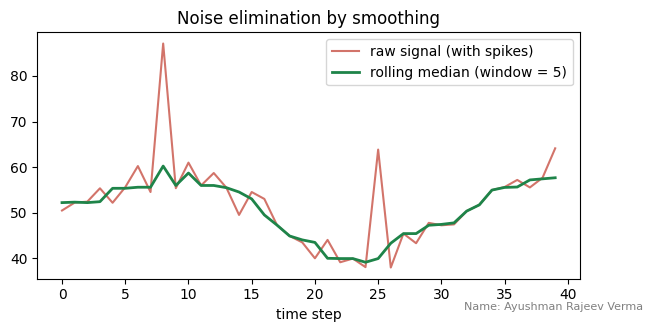

In [2]:
# PART B1 : noise elimination
print("Name: Ayushman Rajeev Verma")
import matplotlib.pyplot as plt

# (a) outliers in price: keep rows whose |z-score| is at most 2.5
price_z = (clean["price"] - clean["price"].mean()) / clean["price"].std()
noisy_rows = clean[price_z.abs() > 2.5]
print("Rows removed as noise (|z| > 2.5):\n", noisy_rows[["sqft", "price"]].to_string())
print("Rows with impossible (non-positive) price:\n", clean[clean["price"] <= 0][["sqft", "price"]].to_string())
no_outliers = clean[price_z.abs() <= 2.5]
data = no_outliers[no_outliers["price"] > 0].reset_index(drop=True)        # impossible values removed too
print("Rows before:", len(clean), "| after noise removal:", len(data))

# (b) smoothing a noisy sensor signal with a moving average
t = np.arange(40)
signal = np.sin(t / 5) * 10 + 50 + rng.normal(0, 2.5, 40)
signal[[8, 25]] += 25                                          # two spikes
smooth = pd.Series(signal).rolling(window=5, center=True, min_periods=1).median()
print("\nSignal std before smoothing:", round(signal.std(), 2), "| after:", round(smooth.std(), 2))

plt.figure(figsize=(7, 3.2))
plt.plot(t, signal, color="#c0392b", alpha=0.7, label="raw signal (with spikes)")
plt.plot(t, smooth, color="#1e8449", lw=2, label="rolling median (window = 5)")
plt.legend(); plt.title("Noise elimination by smoothing"); plt.xlabel("time step")
plt.gcf().text(0.99, 0.005, "Name: Ayushman Rajeev Verma", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p4_noise.png", dpi=110, bbox_inches="tight")
plt.show()

## Part B2: Feature Selection (Variance, Correlation and F-test)

In [3]:
# PART B2 : feature selection
print("Name: Ayushman Rajeev Verma")
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression

features = ["sqft", "bedrooms", "age_years", "distance_km", "price_lakh", "country_code"]
X, y = data[features], data["price"]

# step 1 - remove constant columns
vt = VarianceThreshold(threshold=0.0).fit(X)
print("Constant features removed:", [c for c, keep in zip(features, vt.get_support()) if not keep])
X = X.loc[:, vt.get_support()]

# step 2 - remove one of every pair of highly correlated features (|r| > 0.95)
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
redundant = [c for c in upper.columns if (upper[c] > 0.95).any()]
print("Redundant (correlated) features removed:", redundant)
X = X.drop(columns=redundant)

# step 3 - keep the 3 features most related to price (ANOVA F-test)
sk = SelectKBest(f_regression, k=3).fit(X, y)
scores = pd.Series(sk.scores_, index=X.columns).sort_values(ascending=False)
print("\nF-scores:\n", scores.round(1).to_string())
selected = list(X.columns[sk.get_support()])
print("\nSelected features:", selected)

Name: Ayushman Rajeev Verma
Constant features removed: ['country_code']
Redundant (correlated) features removed: ['price_lakh']

F-scores:
 sqft           335.8
age_years        5.8
bedrooms         1.1
distance_km      0.4

Selected features: ['sqft', 'bedrooms', 'age_years']


## Part C: Exploratory Data Analysis

Name: Ayushman Rajeev Verma
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   sqft       28 non-null     float64
 1   bedrooms   28 non-null     float64
 2   age_years  28 non-null     float64
 3   price      28 non-null     float64
 4   city       28 non-null     object 
dtypes: float64(4), object(1)
memory usage: 1.2+ KB

Statistical summary:
          sqft  bedrooms  age_years      price
count    28.0      28.0       28.0       28.0
mean   1570.2       2.8       20.5  6336250.0
std     501.4       1.1       12.0  2210387.9
min     699.0       1.0        1.0  2491000.0
25%    1137.0       2.0        9.5  4299000.0
50%    1499.0       3.0       20.5  6092500.0
75%    2071.2       4.0       30.0  8426750.0
max    2382.0       4.0       38.0  9510000.0

City-wise average price:
         count       mean
city                    
Mum

/tmp/ipykernel_632/3934717536.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=eda, x="city", y="price", palette="Set2", ax=ax[0, 1]).set_title("Price by city")


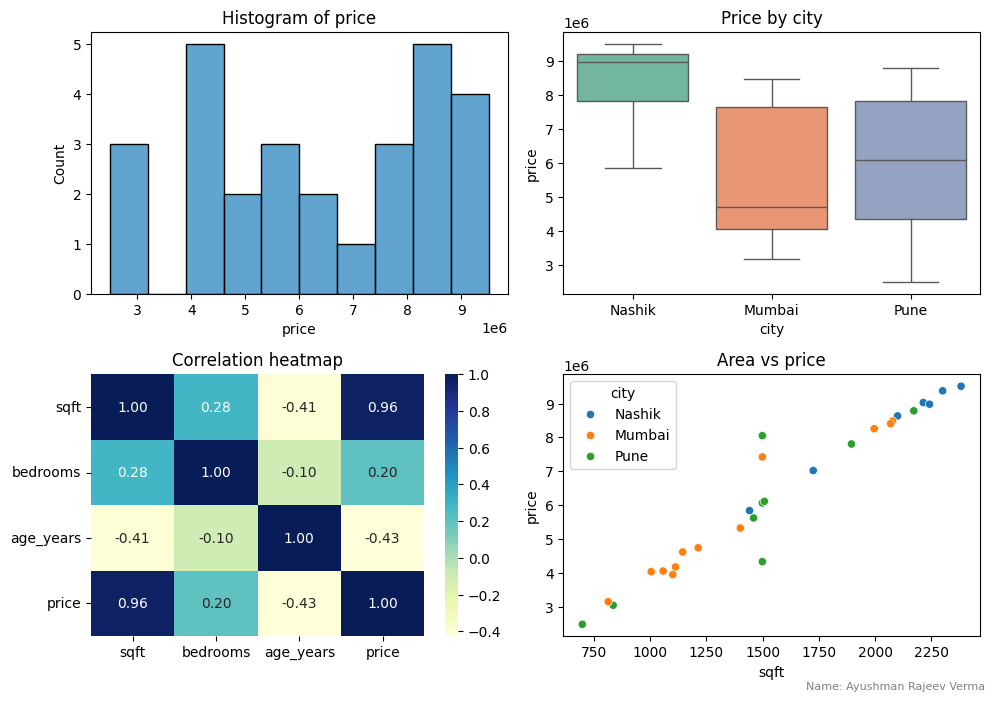

In [4]:
# PART C : exploratory data analysis (EDA)
print("Name: Ayushman Rajeev Verma")
import seaborn as sns
eda = data[selected + ["price", "city"]]

print("Dataset information:")
eda.info()
print("\nStatistical summary:\n", eda.describe().round(1).to_string())
print("\nCity-wise average price:\n", eda.groupby("city")["price"].agg(["count", "mean"]).round(0).to_string())
print("\nCorrelation with price:\n", eda.drop(columns="city").corr()["price"].round(3).to_string())

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
sns.histplot(eda["price"], bins=10, color="#2e86c1", ax=ax[0, 0]).set_title("Histogram of price")
sns.boxplot(data=eda, x="city", y="price", palette="Set2", ax=ax[0, 1]).set_title("Price by city")
sns.heatmap(eda.drop(columns="city").corr(), annot=True, fmt=".2f", cmap="YlGnBu", ax=ax[1, 0]); ax[1, 0].set_title("Correlation heatmap")
sns.scatterplot(data=eda, x="sqft", y="price", hue="city", ax=ax[1, 1]); ax[1, 1].set_title("Area vs price")
plt.tight_layout()
plt.gcf().text(0.99, 0.005, "Name: Ayushman Rajeev Verma", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p4_eda_overview.png", dpi=110, bbox_inches="tight")
plt.show()

**Conclusion:** Missing values were filled with the median or mode, duplicates were removed and the numeric features were normalised and standardised. Extreme prices were removed with a z-score filter and a noisy signal was smoothed. Constant and redundant features were dropped and the most informative features were chosen with an F-test, after which EDA (summary statistics, group averages, correlation heatmap and plots) described the clean data.